In [2]:
# importing modules
# %matplotlib widget 

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pylab import subplot
from matplotlib.colors import LogNorm
from matplotlib.widgets import SpanSelector
from tqdm.auto import tqdm
from scipy.optimize import leastsq
# Lacked in the original code 
from matplotlib import cm
# Using pathlib
from pathlib import Path
# Using pandas
import pandas as pd
# searching for characters
import re
# scienceplots
import scienceplots


# Set environment variables for OpenCV
os.environ['OPENCV_LOG_LEVEL'] = 'FATAL'
os.environ['OPENCV_FFMPEG_LOGLEVEL'] = "-8"

# Setting the graph design
# plt.style.use('science') # requires latex

In [3]:
class ImageStack(object):
    def __init__(self, filename, channel = None):
        # Initialize the ImageStack object
        self.filename = filename
        self.video = cv2.VideoCapture(filename)  # Open the video file
        property_id = int(cv2.CAP_PROP_FRAME_COUNT)  
        length = int(self.video.get(property_id))  # Get the number of frames in the video
        self.frame_count = length  # Store the number of frames
        self.fps = self.video.get(cv2.CAP_PROP_FPS)  # Get the frames per second of the video
        self.channel = channel  # Store the specified channel
        self.shape = self[0].shape

    def __len__(self):
        return self.frame_count  # Return the number of frames in the video
            
    def __getitem__(self, t):
        if t<0: t= len(self)+t-1  # Handle negative indices
        assert t < self.frame_count  # Check if the index is within the range
        self.video.set(cv2.CAP_PROP_POS_FRAMES, t-1)  # Set the position of the video to the desired frame
        success, image = self.video.read()  # Read the frame

        if self.channel is not None:
            return image[...,channel]  # Return the specified channel of the frame
        if image is not None:
            return image.mean(axis=2).astype(int)  # Return the grayscale version of the frame
        self.shape = self[0].shape  # Get the shape of the first frame


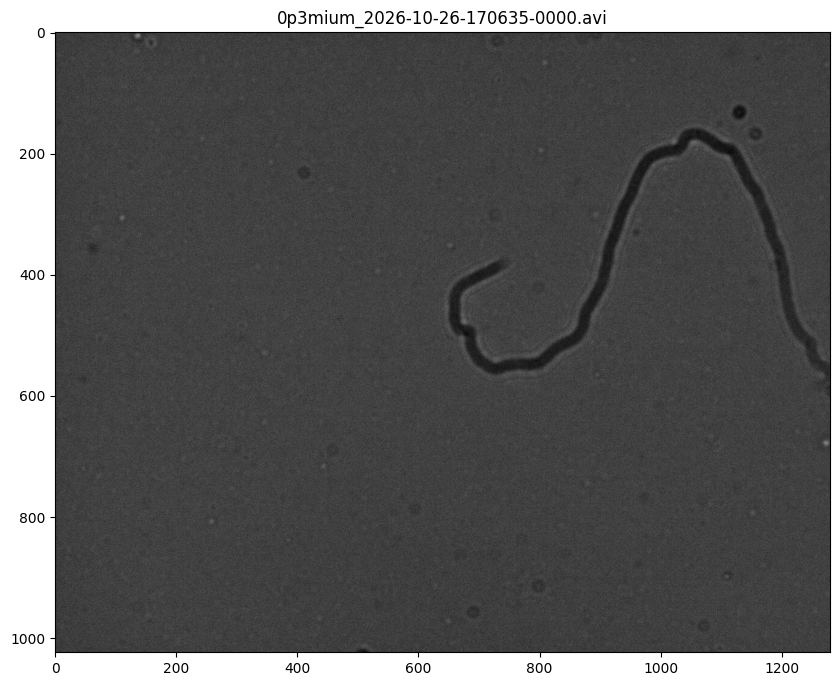

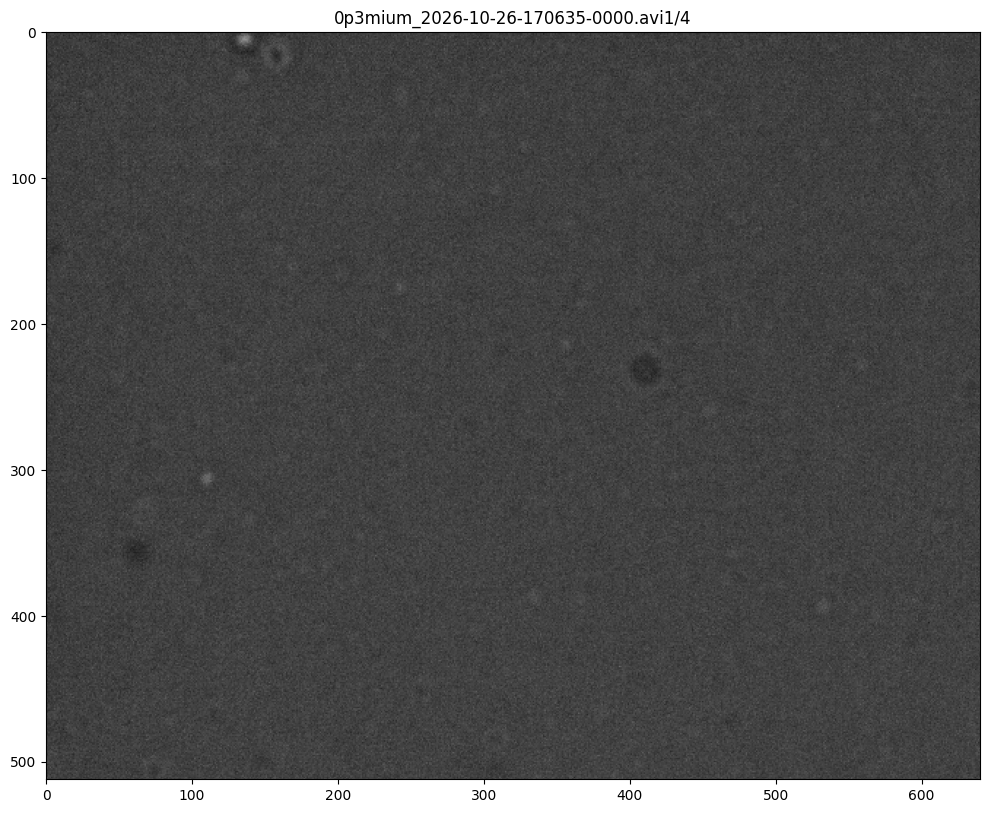

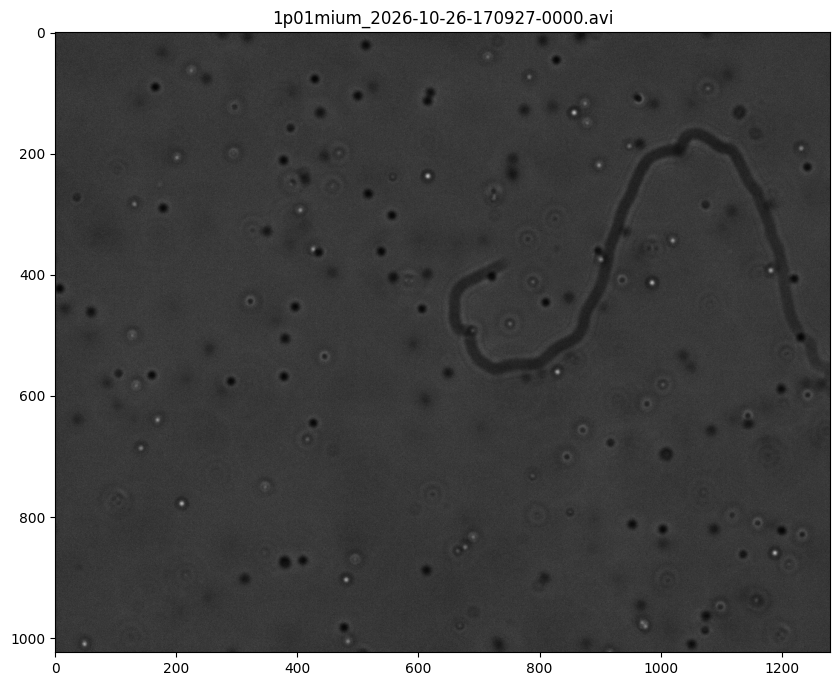

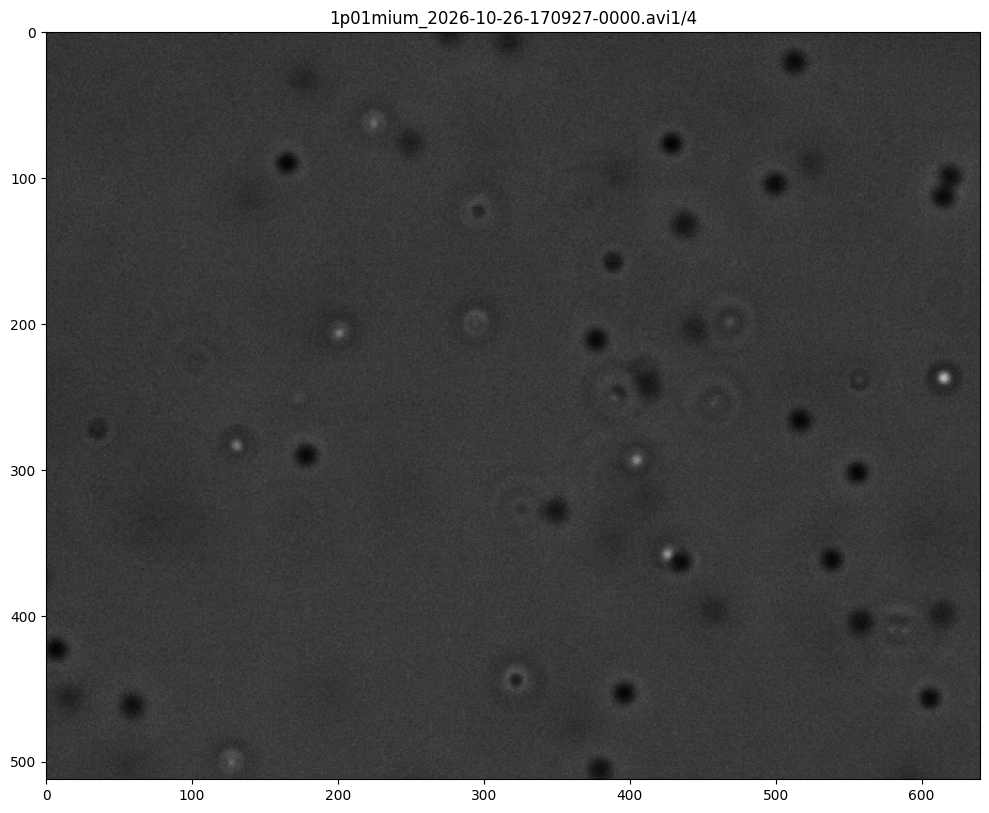

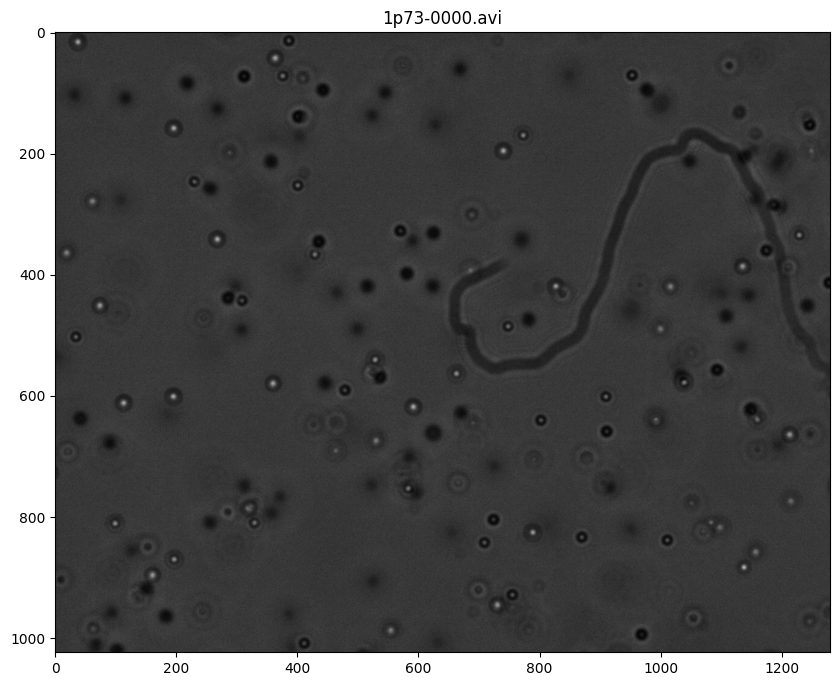

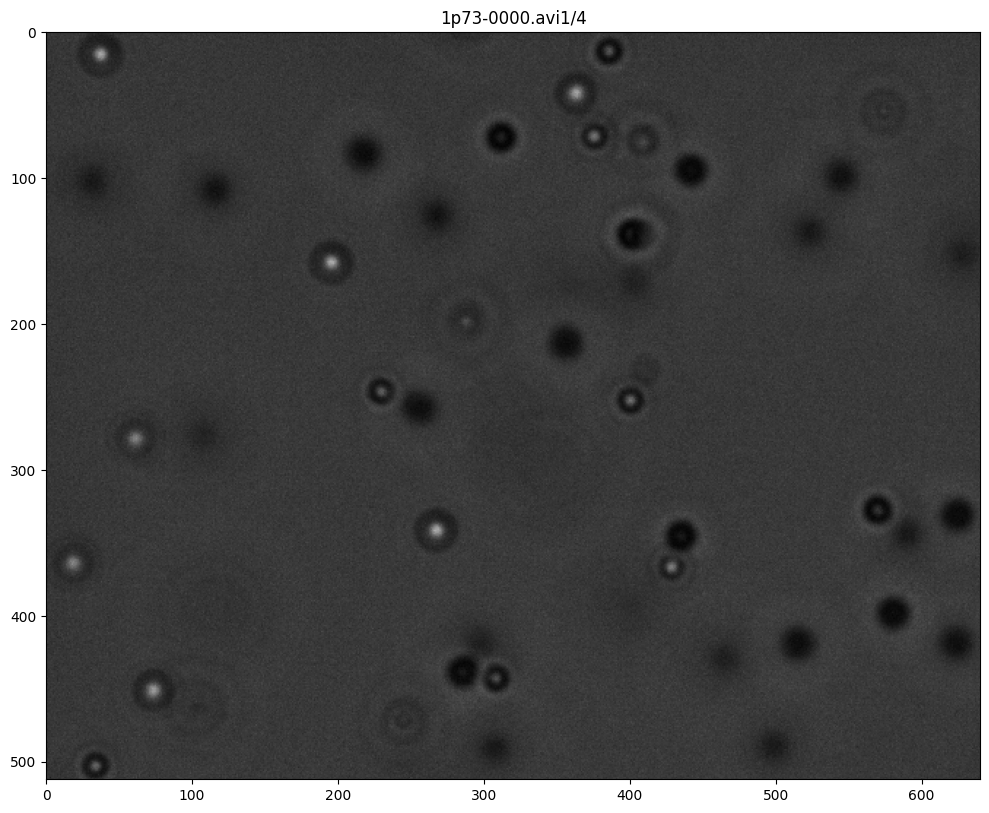

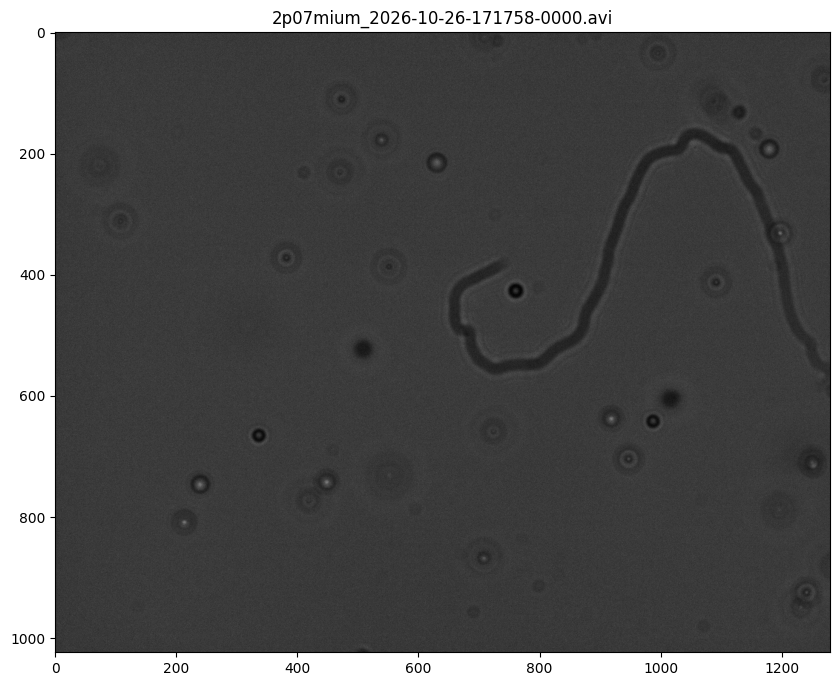

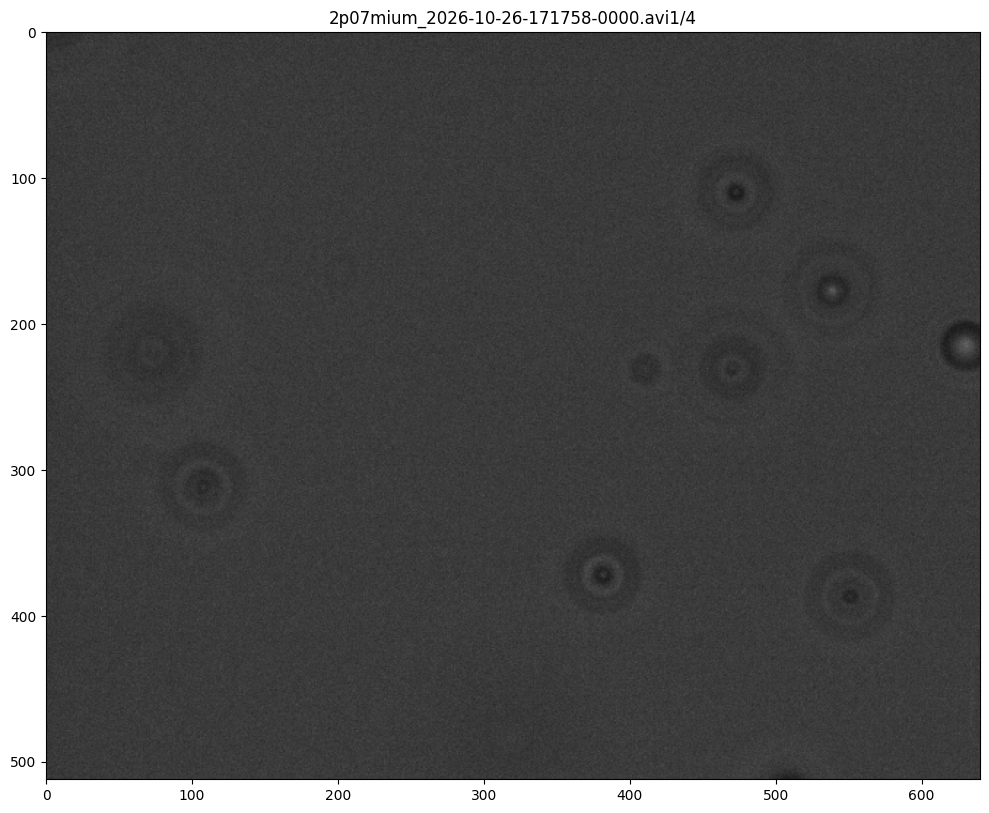

In [17]:
folder_name = '/Volumes/T7 Shield/e1_stand1/data/mixed_with_new_conc_calibration/conc_calibration/'
folder_path = Path(folder_name)
files = list(folder_path.glob('*.avi')) #ref:DDM_py_version.py
div = 2# how smaller region do you want 2^div panels
for file in files:
  stack = ImageStack(file)
  plt.figure(figsize=[10,10])
  plt.imshow(stack[0], cmap='gray')
  plt.title(str(file.name))
  plt.show()
  # print(stack.shape)
  # print(stack.shape[0]/div, stack.shape[1]/div)

  plt.figure(figsize=[10,10])
  plt.imshow(stack[0], cmap='gray')
  plt.xlim(0, stack.shape[1]/div)
  plt.ylim(stack.shape[0]/div, 0)
  plt.title(str(file.name)+'1/{}'.format(div**2))

  plt.tight_layout()
  plt.show()
  